# Optimización de Hiperparámetros

## Parámetros vs Hiperparámetros: La Diferencia Fundamental

Esta es una de las distinciones más importantes en Machine Learning.

### Parámetros (del modelo)

Son valores que el modelo **aprende automáticamente** durante el entrenamiento.

| Modelo | Parámetros aprendidos |
|--------|----------------------|
| Regresión Lineal | Pesos $w$, bias $b$ |
| Red Neuronal | Pesos $W$, biases $b$ de cada capa |
| SVM | Vectores de soporte, multiplicadores $\alpha$ |
| Árbol de Decisión | Puntos de corte, valores de hojas |
| K-Means | Centroides de los clusters |

**Características:**
- Se ajustan **automáticamente** con los datos (gradient descent, etc.)
- Se almacenan en el modelo entrenado
- Su cantidad define la **capacidad** del modelo (ej: 175B parámetros en GPT-3)

### Hiperparámetros

Son valores que el humano (o un algoritmo de búsqueda) define **ANTES** del entrenamiento.

| Modelo | Hiperparámetros |
|--------|----------------|
| Regresión Lineal | Learning rate, regularización λ |
| Red Neuronal | Capas, neuronas, lr, batch size, dropout, activación |
| SVM | C (regularización), kernel, γ |
| Random Forest | n_estimators, max_depth, min_samples_split |
| K-Means | K (número de clusters) |

**Características:**
- Se definen **antes** del entrenamiento
- NO se aprenden de los datos directamente
- Controlan **cómo** aprende el modelo
- Su elección afecta enormemente el rendimiento

### Analogía

```
Parámetros = Lo que el ESTUDIANTE aprende (conocimiento)
              → Se ajustan automáticamente con la práctica

Hiperparámetros = Lo que el PROFESOR decide (metodología)
                   → Horas de estudio, dificultad, orden de temas
                   → Se deciden ANTES de empezar a enseñar
```

### ¿Por qué importa la optimización de hiperparámetros?

```
Mismo modelo + Hiperparámetros malos  → Accuracy: 65%
Mismo modelo + Hiperparámetros buenos → Accuracy: 95%
                                         ↑
                              ¡30 puntos de diferencia!
```

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_digits
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
import warnings
import time
warnings.filterwarnings('ignore')

np.random.seed(42)

# --- Demostración: Parámetros vs Hiperparámetros ---
print("=" * 70)
print("DEMOSTRACIÓN: PARÁMETROS vs HIPERPARÁMETROS")
print("=" * 70)

# Crear dataset
X, y = make_classification(n_samples=500, n_features=20, n_informative=10,
                           n_redundant=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# SVM con diferentes hiperparámetros
configs = [
    {'C': 0.001, 'kernel': 'linear'},
    {'C': 0.1,   'kernel': 'rbf', 'gamma': 'scale'},
    {'C': 1.0,   'kernel': 'rbf', 'gamma': 'scale'},
    {'C': 10.0,  'kernel': 'rbf', 'gamma': 0.1},
    {'C': 100.0, 'kernel': 'rbf', 'gamma': 0.01},
]

print(f"\nModelo: SVM (Support Vector Machine)")
print(f"Dataset: {X_train.shape[0]} train, {X_test.shape[0]} test, {X.shape[1]} features")
print(f"\n{'Hiperparámetros':<35} | {'Accuracy':>10} | {'N° Support Vectors':>20}")
print("-" * 75)

accuracies = []
for config in configs:
    svm = SVC(**config)
    svm.fit(X_train, y_train)
    acc = svm.score(X_test, y_test)
    n_sv = svm.n_support_.sum()
    accuracies.append(acc)

    config_str = ', '.join(f'{k}={v}' for k, v in config.items())
    print(f"  {config_str:<33} | {acc:>9.1%} | {n_sv:>20}")

    # Los PARÁMETROS aprendidos
    if hasattr(svm, 'coef_'):
        print(f"    → Parámetros aprendidos: {svm.coef_.shape[1]} pesos")
    print(f"    → Parámetros aprendidos: {n_sv} vectores de soporte")

print(f"\n💡 Mismo modelo (SVM), mismos datos, pero:")
print(f"   Peor hiperparámetros → {min(accuracies):.1%}")
print(f"   Mejor hiperparámetros → {max(accuracies):.1%}")
print(f"   Diferencia: {(max(accuracies) - min(accuracies))*100:.1f} puntos porcentuales")

DEMOSTRACIÓN: PARÁMETROS vs HIPERPARÁMETROS

Modelo: SVM (Support Vector Machine)
Dataset: 350 train, 150 test, 20 features

Hiperparámetros                     |   Accuracy |   N° Support Vectors
---------------------------------------------------------------------------
  C=0.001, kernel=linear            |     79.3% |                  336
    → Parámetros aprendidos: 20 pesos
    → Parámetros aprendidos: 336 vectores de soporte
  C=0.1, kernel=rbf, gamma=scale    |     87.3% |                  317
    → Parámetros aprendidos: 317 vectores de soporte
  C=1.0, kernel=rbf, gamma=scale    |     91.3% |                  203
    → Parámetros aprendidos: 203 vectores de soporte
  C=10.0, kernel=rbf, gamma=0.1     |     93.3% |                  262
    → Parámetros aprendidos: 262 vectores de soporte
  C=100.0, kernel=rbf, gamma=0.01   |     90.0% |                   97
    → Parámetros aprendidos: 97 vectores de soporte

💡 Mismo modelo (SVM), mismos datos, pero:
   Peor hiperparámetros → 7

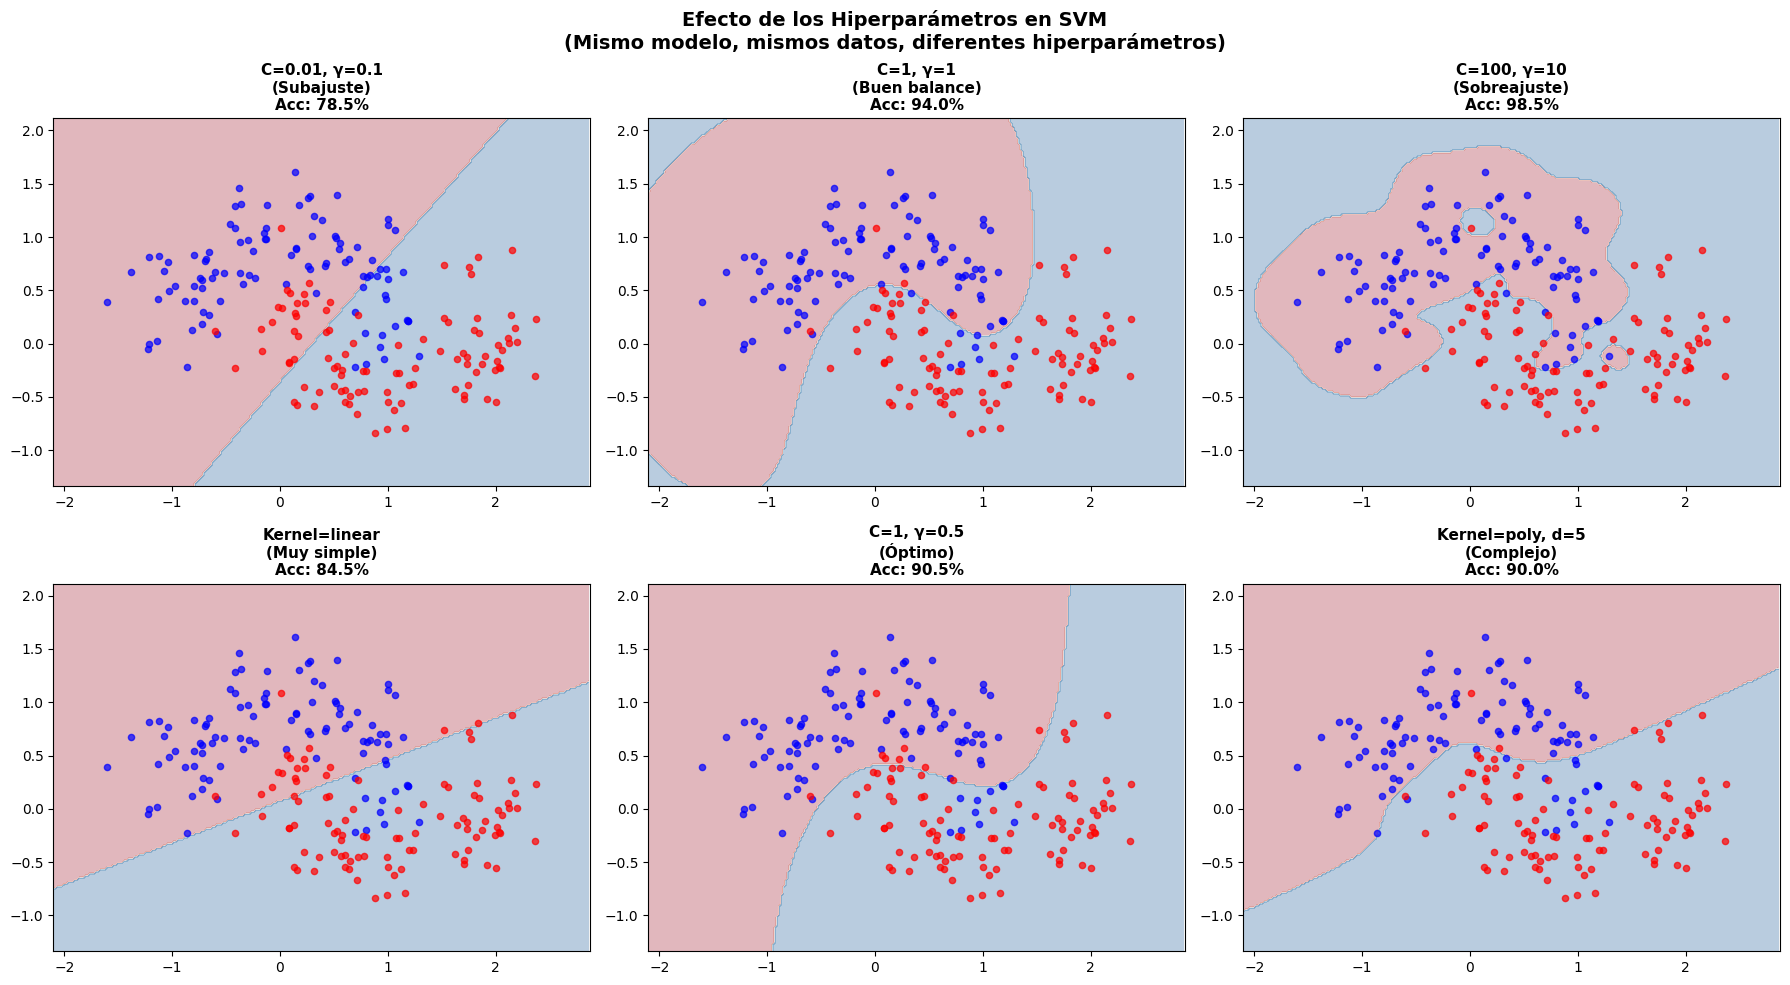

💡 Los hiperparámetros determinan:
   - C (regularización): cuánto penalizar errores de clasificación
   - γ (gamma): radio de influencia de cada punto de soporte
   - kernel: tipo de frontera de decisión (lineal, RBF, polinomial)


In [ ]:
# --- Visualización: Efecto de hiperparámetros en SVM ---
from sklearn.datasets import make_moons

X_vis, y_vis = make_moons(n_samples=200, noise=0.25, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

configs_vis = [
    ({'C': 0.01, 'kernel': 'rbf', 'gamma': 0.1}, 'C=0.01, γ=0.1\n(Subajuste)'),
    ({'C': 1.0, 'kernel': 'rbf', 'gamma': 1.0}, 'C=1, γ=1\n(Buen balance)'),
    ({'C': 100, 'kernel': 'rbf', 'gamma': 10}, 'C=100, γ=10\n(Sobreajuste)'),
    ({'C': 1.0, 'kernel': 'linear'}, 'Kernel=linear\n(Muy simple)'),
    ({'C': 1.0, 'kernel': 'rbf', 'gamma': 0.5}, 'C=1, γ=0.5\n(Óptimo)'),
    ({'C': 1.0, 'kernel': 'poly', 'degree': 5}, 'Kernel=poly, d=5\n(Complejo)'),
]

for idx, (config, title) in enumerate(configs_vis):
    row, col = idx // 3, idx % 3

    svm = SVC(**config)
    svm.fit(X_vis, y_vis)
    acc = svm.score(X_vis, y_vis)

    # Malla para decision boundary
    h = 0.02
    x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
    y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    axes[row, col].contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
    axes[row, col].scatter(X_vis[y_vis==0, 0], X_vis[y_vis==0, 1], c='blue', s=20, alpha=0.7)
    axes[row, col].scatter(X_vis[y_vis==1, 0], X_vis[y_vis==1, 1], c='red', s=20, alpha=0.7)
    axes[row, col].set_title(f'{title}\nAcc: {acc:.1%}', fontsize=11, fontweight='bold')
    axes[row, col].set_xlim(x_min, x_max)
    axes[row, col].set_ylim(y_min, y_max)

plt.suptitle('Efecto de los Hiperparámetros en SVM\n(Mismo modelo, mismos datos, diferentes hiperparámetros)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Los hiperparámetros determinan:")
print("   - C (regularización): cuánto penalizar errores de clasificación")
print("   - γ (gamma): radio de influencia de cada punto de soporte")
print("   - kernel: tipo de frontera de decisión (lineal, RBF, polinomial)")

## Grid Search (Búsqueda en Grilla)

### Idea
Evaluar **todas las combinaciones posibles** de hiperparámetros en una grilla predefinida.

```
         C = [0.1, 1, 10]
         γ = [0.01, 0.1, 1]
         
         γ=0.01  γ=0.1   γ=1
C=0.1  │ 0.72  │ 0.78  │ 0.65 │
C=1    │ 0.80  │ 0.92  │ 0.75 │  ← Evalúa TODAS
C=10   │ 0.82  │ 0.88  │ 0.70 │     las 9 combinaciones
```

### Ventajas y Desventajas

| ✅ Ventajas | ❌ Desventajas |
|-------------|---------------|
| Simple e intuitivo | Crece exponencialmente: $O(n_1 \times n_2 \times ... \times n_k)$ |
| Garantiza encontrar el mejor en la grilla | Ineficiente en dimensiones altas |
| Fácil de paralelizar | Desperdicia evaluaciones en regiones malas |
| Reproducible | No explora entre los puntos de la grilla |

In [ ]:
# =============================================================================
# GRID SEARCH - Implementación desde cero
# =============================================================================
from itertools import product

def grid_search(modelo_cls, param_grid, X_train, y_train, cv=5, scoring='accuracy'):
    """
    Grid Search desde cero.

    Evalúa TODAS las combinaciones de hiperparámetros.
    """
    # Generar todas las combinaciones
    keys = list(param_grid.keys())
    values = list(param_grid.values())
    combinations = list(product(*values))

    resultados = []
    mejor_score = -np.inf
    mejor_params = None

    print(f"Grid Search: {len(combinations)} combinaciones a evaluar")
    print("-" * 60)

    for i, combo in enumerate(combinations):
        params = dict(zip(keys, combo))

        # Cross-validation
        modelo = modelo_cls(**params)
        scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring=scoring)
        mean_score = scores.mean()
        std_score = scores.std()

        resultados.append({
            'params': params,
            'mean_score': mean_score,
            'std_score': std_score,
            'scores': scores
        })

        if mean_score > mejor_score:
            mejor_score = mean_score
            mejor_params = params

    # Ordenar por score
    resultados.sort(key=lambda x: x['mean_score'], reverse=True)

    return mejor_params, mejor_score, resultados

# --- Ejemplo: Grid Search en SVM ---
param_grid_svm = {
    'C': [0.01, 0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

start = time.time()
mejor_params, mejor_score, resultados_grid = grid_search(
    SVC, param_grid_svm, X_train, y_train, cv=5
)
tiempo_grid = time.time() - start

print(f"\n{'='*60}")
print(f"RESULTADO Grid Search")
print(f"{'='*60}")
print(f"  Mejor score: {mejor_score:.4f}")
print(f"  Mejor params: {mejor_params}")
print(f"  Evaluaciones: {len(resultados_grid)}")
print(f"  Tiempo: {tiempo_grid:.2f}s")
print(f"\n  Top 5 combinaciones:")
for i, r in enumerate(resultados_grid[:5]):
    print(f"    {i+1}. {r['mean_score']:.4f} (±{r['std_score']:.4f}) → {r['params']}")

Grid Search: 20 combinaciones a evaluar
------------------------------------------------------------

RESULTADO Grid Search
  Mejor score: 0.9229
  Mejor params: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
  Evaluaciones: 20
  Tiempo: 1.95s

  Top 5 combinaciones:
    1. 0.9229 (±0.0232) → {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
    2. 0.9229 (±0.0232) → {'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}
    3. 0.9200 (±0.0368) → {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
    4. 0.8943 (±0.0321) → {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
    5. 0.8714 (±0.0338) → {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}


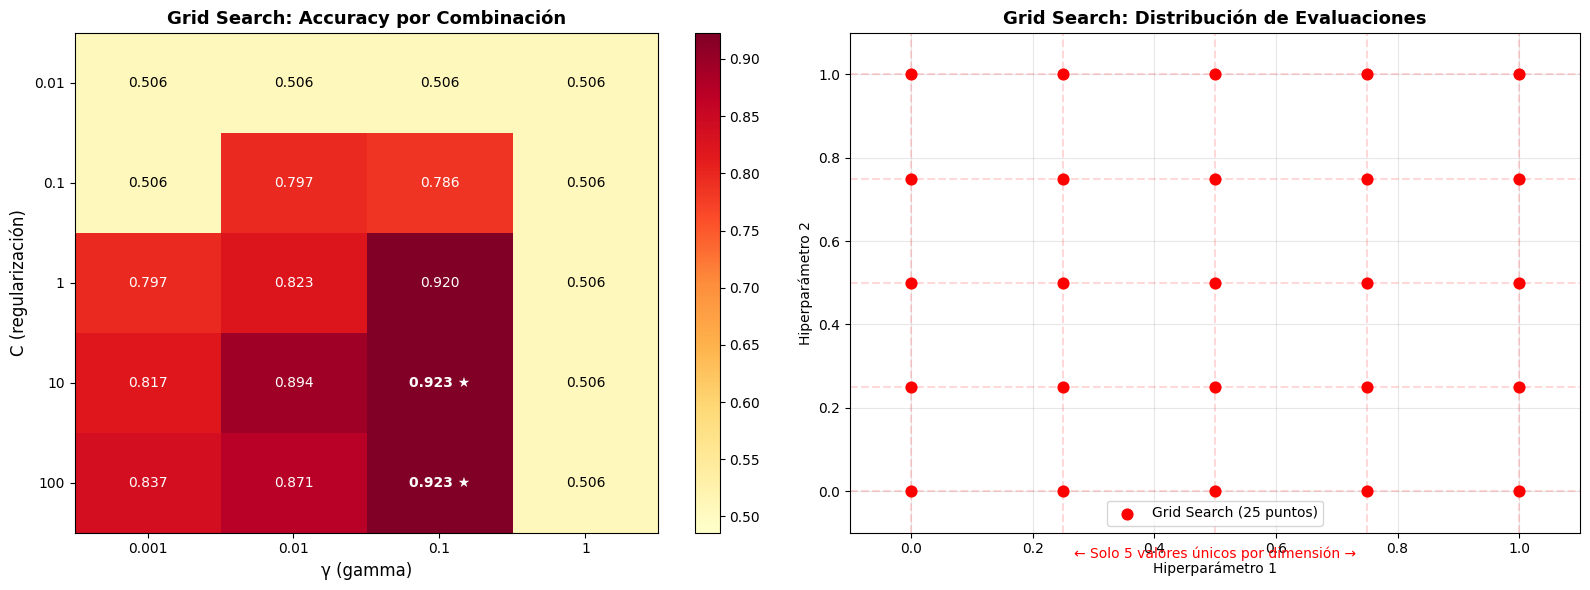

In [ ]:
# --- Visualizar la grilla de resultados ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mapa de calor C vs gamma
C_vals = param_grid_svm['C']
gamma_vals = param_grid_svm['gamma']
score_matrix = np.zeros((len(C_vals), len(gamma_vals)))

for r in resultados_grid:
    i = C_vals.index(r['params']['C'])
    j = gamma_vals.index(r['params']['gamma'])
    score_matrix[i, j] = r['mean_score']

im = axes[0].imshow(score_matrix, cmap='YlOrRd', aspect='auto', vmin=score_matrix.min()-0.02)
axes[0].set_xticks(range(len(gamma_vals)))
axes[0].set_yticks(range(len(C_vals)))
axes[0].set_xticklabels([str(g) for g in gamma_vals])
axes[0].set_yticklabels([str(c) for c in C_vals])
axes[0].set_xlabel('γ (gamma)', fontsize=12)
axes[0].set_ylabel('C (regularización)', fontsize=12)
axes[0].set_title('Grid Search: Accuracy por Combinación', fontsize=13, fontweight='bold')

for i in range(len(C_vals)):
    for j in range(len(gamma_vals)):
        best = score_matrix[i, j] == score_matrix.max()
        color = 'white' if score_matrix[i, j] > score_matrix.mean() else 'black'
        marker = ' ★' if best else ''
        axes[0].text(j, i, f'{score_matrix[i, j]:.3f}{marker}',
                    ha='center', va='center', fontsize=10, color=color,
                    fontweight='bold' if best else 'normal')
plt.colorbar(im, ax=axes[0])

# Problema del grid search: distribución uniforme de evaluaciones
np.random.seed(42)
grid_points_x = np.repeat(np.linspace(0, 1, 5), 5)
grid_points_y = np.tile(np.linspace(0, 1, 5), 5)

axes[1].scatter(grid_points_x, grid_points_y, c='red', s=60, zorder=5, label='Grid Search (25 puntos)')
axes[1].set_xlabel('Hiperparámetro 1')
axes[1].set_ylabel('Hiperparámetro 2')
axes[1].set_title('Grid Search: Distribución de Evaluaciones', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].set_xlim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(True, alpha=0.3)

# Mostrar que solo explora 5 valores únicos por dimensión
for v in np.linspace(0, 1, 5):
    axes[1].axhline(y=v, color='red', alpha=0.15, linestyle='--')
    axes[1].axvline(x=v, color='red', alpha=0.15, linestyle='--')
axes[1].text(0.5, -0.05, '← Solo 5 valores únicos por dimensión →',
            ha='center', fontsize=10, color='red', transform=axes[1].transAxes)

plt.tight_layout()
plt.show()

## Random Search + Teoría de Bergstra & Bengio (2012)

### El paper que cambió todo

En 2012, Bergstra & Bengio publicaron **"Random Search for Hyper-Parameter Optimization"**,
demostrando que Random Search es **sorprendentemente superior** a Grid Search.

### La intuición clave

No todos los hiperparámetros son **igualmente importantes**.
Si un hiperparámetro es más importante que otro, Grid Search desperdicia evaluaciones:

```
Grid Search (9 puntos):              Random Search (9 puntos):
      ┌─────────────────┐                 ┌─────────────────┐
      │ •    •    •     │                 │     •    •      │
      │                 │                 │  •          •   │
      │ •    •    •     │ ← Solo 3        │       •         │ ← 9 valores
      │                 │   valores       │ •         •     │   únicos por
      │ •    •    •     │   únicos por    │    •         •  │   dimensión!
      └─────────────────┘   dimensión     └─────────────────┘
       Hiperparámetro 1                    Hiperparámetro 1
       (IMPORTANTE)                        (IMPORTANTE)
```

### El argumento formal de Bergstra & Bengio

Si el hiperparámetro 1 es **mucho más importante** que el 2:

- **Grid Search** con $n^2$ puntos explora solo $n$ valores del parámetro importante
- **Random Search** con $n^2$ puntos explora $n^2$ valores del parámetro importante

> *"For most datasets only a few of the hyper-parameters really matter,
> but that different hyper-parameters are important on different datasets."*
> — Bergstra & Bengio, 2012

### El resultado teórico

Con Random Search y $n$ evaluaciones, la probabilidad de encontrar un punto
en el top $\alpha$% del espacio es:

$$P(\text{encontrar top } \alpha\%) = 1 - (1 - \alpha)^n$$

Para encontrar algo en el **top 5%** con 95% de confianza:
$$0.95 = 1 - (1-0.05)^n \implies n = \frac{\log(0.05)}{\log(0.95)} \approx 60$$

¡Solo 60 evaluaciones aleatorias para casi garantizar un buen resultado!

In [ ]:
# =============================================================================
# RANDOM SEARCH - Implementación desde cero
# =============================================================================

def random_search(modelo_cls, param_distributions, X_train, y_train,
                  n_iter=20, cv=5, scoring='accuracy', random_state=42):
    """
    Random Search desde cero.

    Muestrea n_iter combinaciones aleatorias del espacio de hiperparámetros.
    """
    rng = np.random.RandomState(random_state)
    resultados = []
    mejor_score = -np.inf
    mejor_params = None

    print(f"Random Search: {n_iter} evaluaciones aleatorias")
    print("-" * 60)

    for i in range(n_iter):
        # Muestrear parámetros aleatorios
        params = {}
        for key, dist in param_distributions.items():
            if isinstance(dist, list):
                # Lista: elegir uno al azar
                params[key] = rng.choice(dist)
            elif isinstance(dist, tuple) and len(dist) == 3:
                # Tupla (low, high, 'log'): muestreo log-uniforme
                low, high, scale = dist
                if scale == 'log':
                    params[key] = float(np.exp(rng.uniform(np.log(low), np.log(high))))
                else:
                    params[key] = float(rng.uniform(low, high))
            elif isinstance(dist, tuple) and len(dist) == 2:
                low, high = dist
                if isinstance(low, int):
                    params[key] = int(rng.randint(low, high + 1))
                else:
                    params[key] = float(rng.uniform(low, high))

        # Cross-validation
        modelo = modelo_cls(**params)
        scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring=scoring)
        mean_score = scores.mean()

        resultados.append({
            'params': params,
            'mean_score': mean_score,
            'std_score': scores.std(),
            'iteration': i
        })

        if mean_score > mejor_score:
            mejor_score = mean_score
            mejor_params = params.copy()

    resultados.sort(key=lambda x: x['mean_score'], reverse=True)
    return mejor_params, mejor_score, resultados

# --- Random Search en SVM ---
param_distributions_svm = {
    'C': (0.01, 100, 'log'),        # Log-uniforme: muy importante para C
    'gamma': (0.001, 10, 'log'),     # Log-uniforme
    'kernel': ['rbf'],
}

start = time.time()
mejor_params_rs, mejor_score_rs, resultados_random = random_search(
    SVC, param_distributions_svm, X_train, y_train, n_iter=20, cv=5
)
tiempo_random = time.time() - start

print(f"\n{'='*60}")
print(f"RESULTADO Random Search ({len(resultados_random)} evaluaciones)")
print(f"{'='*60}")
print(f"  Mejor score: {mejor_score_rs:.4f}")
print(f"  Mejor params: C={mejor_params_rs['C']:.4f}, γ={mejor_params_rs['gamma']:.6f}")
print(f"  Tiempo: {tiempo_random:.2f}s")

# Comparar con Grid Search
print(f"\n📊 Comparación:")
print(f"  Grid Search:   {mejor_score:.4f} ({len(resultados_grid)} evaluaciones, {tiempo_grid:.2f}s)")
print(f"  Random Search: {mejor_score_rs:.4f} ({len(resultados_random)} evaluaciones, {tiempo_random:.2f}s)")

Random Search: 20 evaluaciones aleatorias
------------------------------------------------------------

RESULTADO Random Search (20 evaluaciones)
  Mejor score: 0.9200
  Mejor params: C=5.4567, γ=0.057625
  Tiempo: 1.23s

📊 Comparación:
  Grid Search:   0.9229 (20 evaluaciones, 1.95s)
  Random Search: 0.9200 (20 evaluaciones, 1.23s)


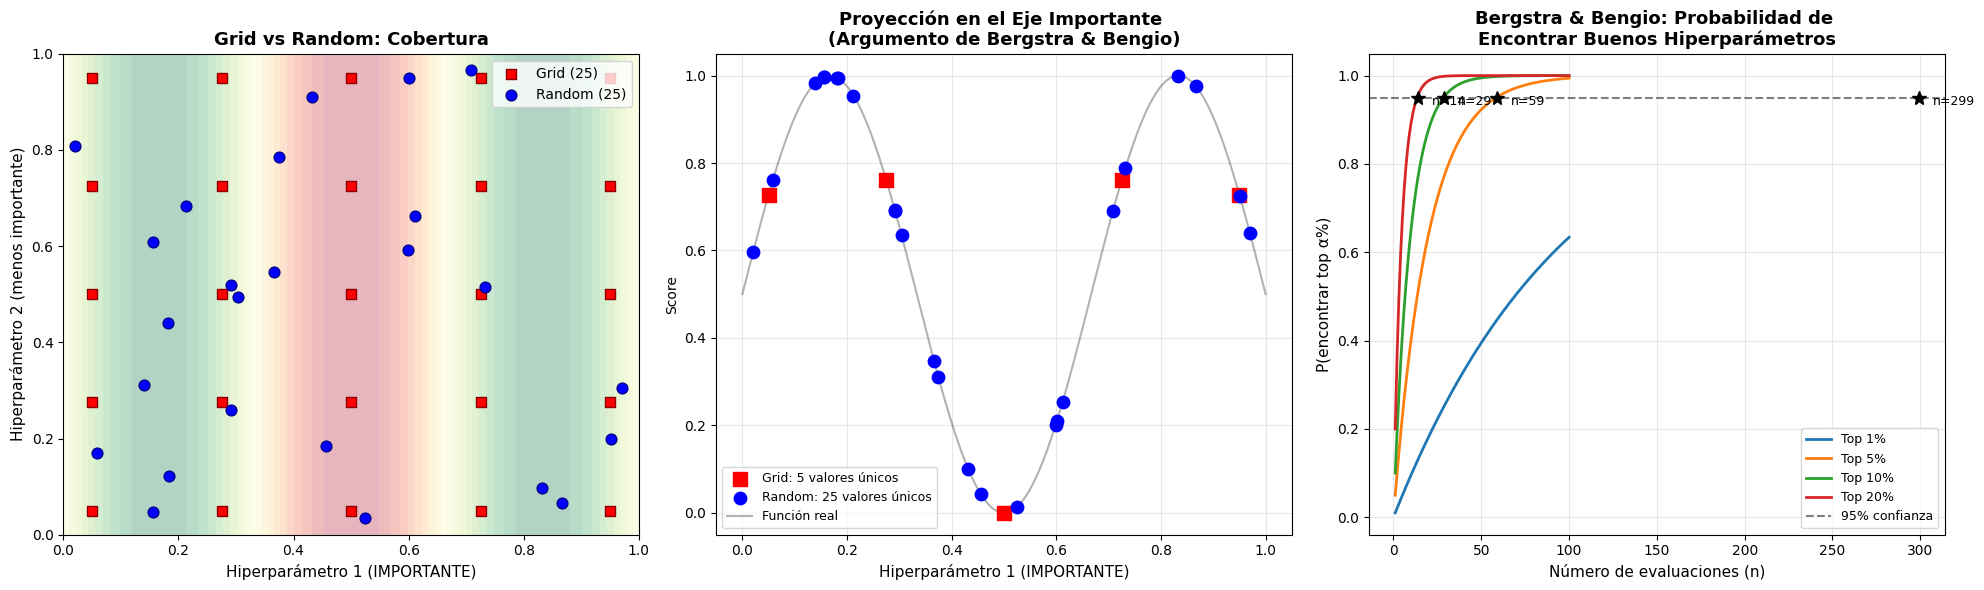


📖 Resultado clave de Bergstra & Bengio (2012):
   - Random Search con N puntos explora N valores únicos por dimensión
   - Grid Search con N=n^d puntos explora solo n valores por dimensión
   - Con ~60 evaluaciones aleatorias, hay 95% de probabilidad
     de encontrar un hiperparámetro en el top 5%


In [ ]:
# --- Demostración visual de Bergstra & Bengio ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Grid vs Random: cobertura del espacio
np.random.seed(42)
n_points = 25

# Grid: 5×5
gx = np.repeat(np.linspace(0.05, 0.95, 5), 5)
gy = np.tile(np.linspace(0.05, 0.95, 5), 5)

# Random: 25 puntos
rx = np.random.uniform(0, 1, n_points)
ry = np.random.uniform(0, 1, n_points)

# Función objetivo: solo depende del eje X (Hiperparámetro 1 es más importante)
def f_objective(x, y):
    return np.sin(3 * np.pi * x) * 0.5 + 0.5  # Solo depende de x

# Colorear por valor de la función objetivo
ax = axes[0]
# Fondo: importancia
xx, yy = np.meshgrid(np.linspace(0, 1, 100), np.linspace(0, 1, 100))
zz = f_objective(xx, yy)
ax.contourf(xx, yy, zz, levels=20, cmap='RdYlGn', alpha=0.3)
ax.scatter(gx, gy, c='red', s=60, marker='s', zorder=5, label=f'Grid ({n_points})', edgecolors='darkred')
ax.scatter(rx, ry, c='blue', s=60, marker='o', zorder=5, label=f'Random ({n_points})', edgecolors='darkblue')
ax.set_xlabel('Hiperparámetro 1 (IMPORTANTE)', fontsize=11)
ax.set_ylabel('Hiperparámetro 2 (menos importante)', fontsize=11)
ax.set_title('Grid vs Random: Cobertura', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)

# 2. Proyección en el eje importante
ax2 = axes[1]
# Grid: solo 5 valores únicos en eje X
gx_unique = np.unique(gx)
rx_sorted = np.sort(rx)

ax2.scatter(gx_unique, f_objective(gx_unique, 0), c='red', s=100, marker='s',
           label=f'Grid: {len(gx_unique)} valores únicos', zorder=5)
ax2.scatter(rx_sorted, f_objective(rx_sorted, 0), c='blue', s=80, marker='o',
           label=f'Random: {n_points} valores únicos', zorder=5)
x_fine = np.linspace(0, 1, 200)
ax2.plot(x_fine, f_objective(x_fine, 0), 'k-', alpha=0.3, label='Función real')
ax2.set_xlabel('Hiperparámetro 1 (IMPORTANTE)', fontsize=11)
ax2.set_ylabel('Score')
ax2.set_title('Proyección en el Eje Importante \n(Argumento de Bergstra & Bengio)', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# 3. Probabilidad teórica de éxito
ax3 = axes[2]
n_evals = np.arange(1, 101)
alphas = [0.01, 0.05, 0.10, 0.20]
for alpha in alphas:
    prob = 1 - (1 - alpha)**n_evals
    ax3.plot(n_evals, prob, linewidth=2, label=f'Top {alpha:.0%}')
    # Marcar n para 95% de confianza
    n_95 = int(np.ceil(np.log(0.05) / np.log(1 - alpha)))
    ax3.plot(n_95, 0.95, 'k*', markersize=10)
    ax3.annotate(f'n={n_95}', (n_95, 0.95), textcoords="offset points",
                xytext=(10, -5), fontsize=9)

ax3.axhline(y=0.95, color='black', linestyle='--', alpha=0.5, label='95% confianza')
ax3.set_xlabel('Número de evaluaciones (n)', fontsize=11)
ax3.set_ylabel('P(encontrar top α%)', fontsize=11)
ax3.set_title('Bergstra & Bengio: Probabilidad de \nEncontrar Buenos Hiperparámetros', fontsize=13, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📖 Resultado clave de Bergstra & Bengio (2012):")
print("   - Random Search con N puntos explora N valores únicos por dimensión")
print("   - Grid Search con N=n^d puntos explora solo n valores por dimensión")
print("   - Con ~60 evaluaciones aleatorias, hay 95% de probabilidad")
print("     de encontrar un hiperparámetro en el top 5%")

## Optimización Bayesiana

### Idea: Búsqueda Inteligente que Aprende

Grid y Random son "ciegos" — no usan información de evaluaciones previas.
La optimización bayesiana **construye un modelo del espacio** y busca inteligentemente.

```
Iteración 1: Evaluar punto aleatorio → score = 0.75
Iteración 2: Evaluar punto aleatorio → score = 0.82
Iteración 3: ¡El modelo sugiere dónde buscar! → score = 0.91  ← Inteligente
Iteración 4: El modelo refina la búsqueda → score = 0.93
...
```

### Componentes

1. **Modelo sustituto** (surrogate model): Aproxima la función objetivo
   - **Gaussian Process (GP)**: Modela una distribución sobre funciones
   - **TPE** (Tree-Parzen Estimator): Modela P(x|y) con KDE

2. **Función de adquisición**: Decide dónde evaluar next
   - **EI** (Expected Improvement): $EI(x) = \mathbb{E}[\max(f(x) - f^+, 0)]$
   - **UCB** (Upper Confidence Bound): $UCB(x) = \mu(x) + \kappa \cdot \sigma(x)$
   - **PI** (Probability of Improvement): $PI(x) = P(f(x) > f^+)$

### Gaussian Process (GP)

El GP modela la función objetivo como una distribución:

$$f(x) \sim \mathscr{GP}(\mu(x), k(x, x'))$$

Donde:
- $\mu(x)$: media predicha en el punto $x$
- $k(x, x')$: kernel (ej: RBF) que mide similitud entre puntos
- La **incertidumbre** $\sigma(x)$ es alta donde no hemos evaluado

### Expected Improvement (EI)

$$EI(x) = (\mu(x) - f^+ - \xi) \cdot \Phi(Z) + \sigma(x) \cdot \phi(Z)$$

Donde $Z = \frac{\mu(x) - f^+ - \xi}{\sigma(x)}$, $\Phi$ es la CDF normal, y $\phi$ la PDF.

**Balance exploración-explotación:**
- $\mu(x) - f^+$: **Explotación** (buscar donde el modelo predice alto)
- $\sigma(x)$: **Exploración** (buscar donde hay incertidumbre)

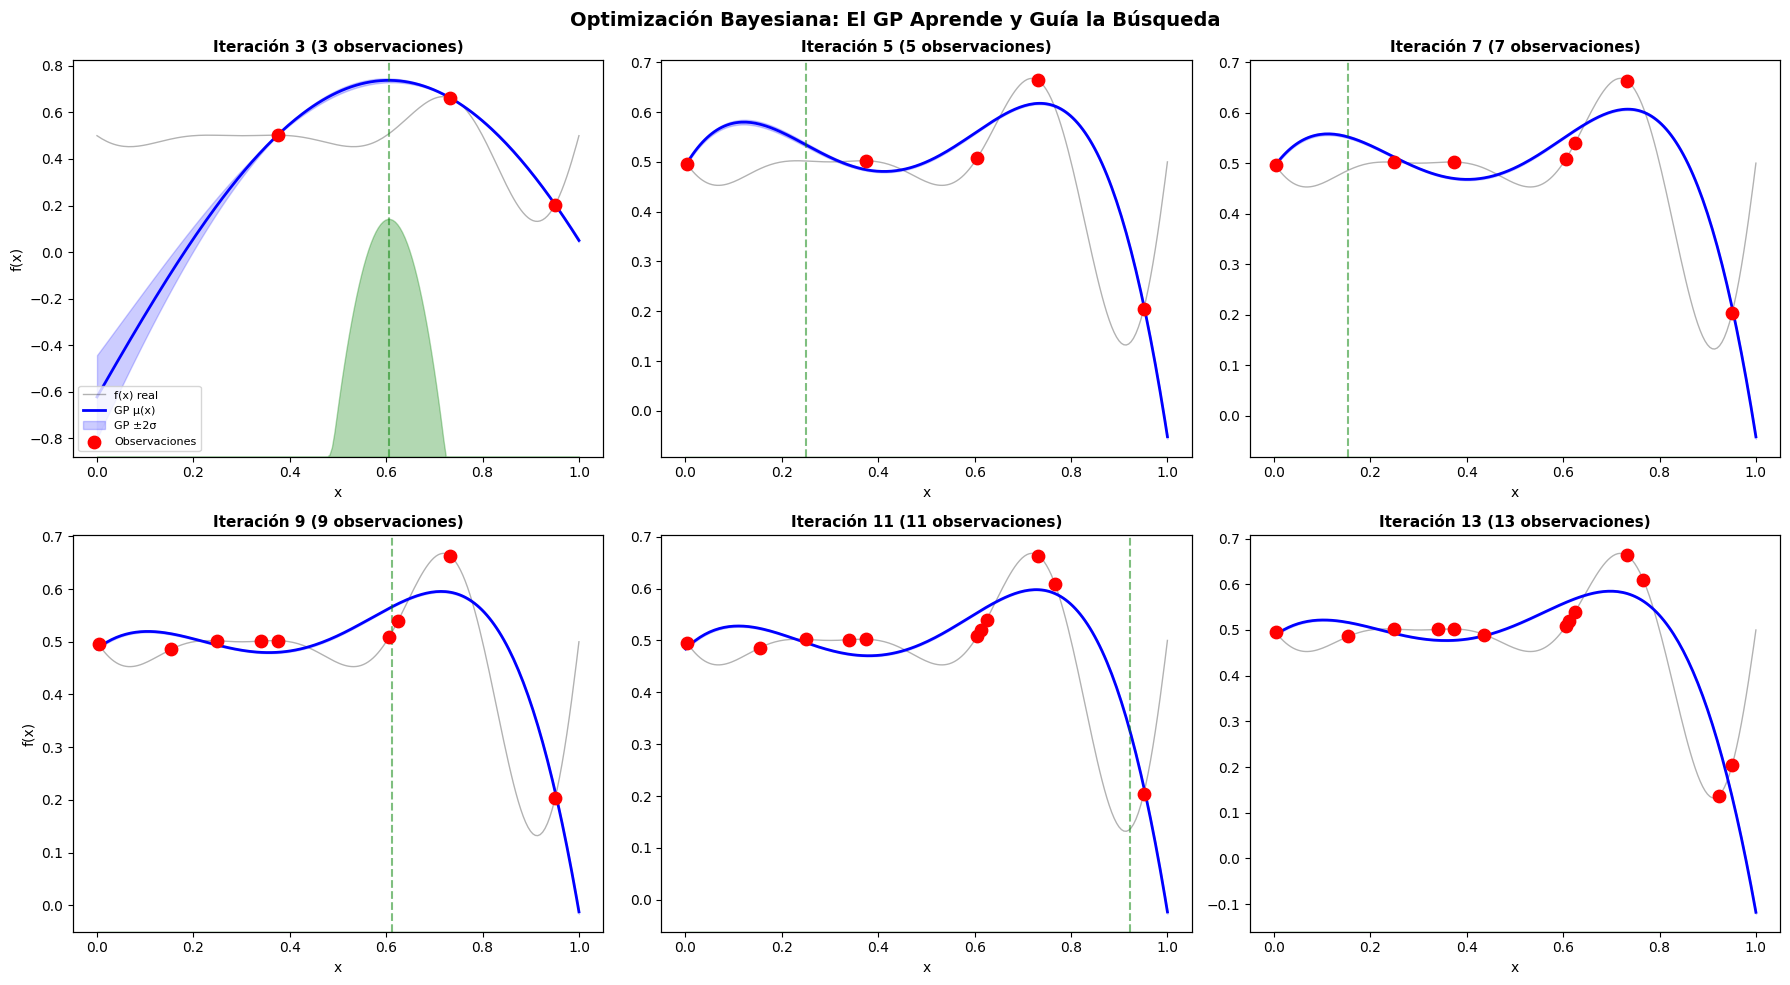


✅ Mejor resultado: x=0.7320, f(x)=0.6635
   El GP (azul) se ajusta cada vez mejor a la función real (negro)
   EI (verde) indica dónde buscar: alto donde hay incertidumbre + promesa


In [ ]:
# =============================================================================
# OPTIMIZACIÓN BAYESIANA - Implementación desde cero
# =============================================================================
from scipy.stats import norm
from scipy.optimize import minimize

class OptimizacionBayesiana:
    """
    Optimización Bayesiana con Gaussian Process como modelo sustituto
    y Expected Improvement como función de adquisición.
    """

    def __init__(self, bounds, random_state=42):
        self.bounds = np.array(bounds)  # [(low, high), ...]
        self.n_dims = len(bounds)
        self.rng = np.random.RandomState(random_state)

        # Historial
        self.X_observados = []
        self.y_observados = []

    def _kernel_rbf(self, X1, X2, length_scale=1.0, signal_var=1.0):
        """Kernel RBF (Radial Basis Function)."""
        dist_sq = np.sum((X1[:, np.newaxis, :] - X2[np.newaxis, :, :]) ** 2, axis=2)
        return signal_var * np.exp(-0.5 * dist_sq / length_scale**2)

    def _gp_predict(self, X_new, noise=1e-6):
        """Predicción del Gaussian Process."""
        if len(self.X_observados) == 0:
            return np.zeros(len(X_new)), np.ones(len(X_new))

        X_obs = np.array(self.X_observados)
        y_obs = np.array(self.y_observados)

        # Matrices de kernel
        K = self._kernel_rbf(X_obs, X_obs) + noise * np.eye(len(X_obs))
        K_star = self._kernel_rbf(X_new, X_obs)
        K_star_star = self._kernel_rbf(X_new, X_new)

        # Predicción GP
        K_inv = np.linalg.inv(K)
        mu = K_star @ K_inv @ y_obs
        sigma = np.sqrt(np.diag(K_star_star - K_star @ K_inv @ K_star.T).clip(min=1e-10))

        return mu, sigma

    def _expected_improvement(self, X_new, xi=0.01):
        """Expected Improvement (función de adquisición)."""
        mu, sigma = self._gp_predict(X_new)

        if len(self.y_observados) == 0:
            return np.ones(len(X_new))

        y_best = np.max(self.y_observados)

        with np.errstate(divide='warn'):
            Z = (mu - y_best - xi) / sigma
            ei = (mu - y_best - xi) * norm.cdf(Z) + sigma * norm.pdf(Z)
            ei[sigma < 1e-10] = 0.0

        return ei

    def sugerir_siguiente(self, n_candidates=1000):
        """Sugiere el siguiente punto a evaluar maximizando EI."""
        # Generar candidatos aleatorios
        candidates = np.column_stack([
            self.rng.uniform(b[0], b[1], n_candidates) for b in self.bounds
        ])

        # Calcular EI para cada candidato
        ei = self._expected_improvement(candidates)

        # Devolver el candidato con mayor EI
        best_idx = np.argmax(ei)
        return candidates[best_idx], ei

    def observar(self, x, y):
        """Registra una observación."""
        self.X_observados.append(x)
        self.y_observados.append(y)

    def optimizar(self, funcion_objetivo, n_init=5, n_iter=20):
        """
        Loop principal de optimización bayesiana.

        1. Inicializar con puntos aleatorios
        2. Repetir:
           a. Ajustar GP a las observaciones
           b. Maximizar EI para encontrar el siguiente punto
           c. Evaluar la función objetivo
           d. Actualizar observaciones
        """
        # Fase 1: Inicialización aleatoria
        for _ in range(n_init):
            x = np.array([self.rng.uniform(b[0], b[1]) for b in self.bounds])
            y = funcion_objetivo(x)
            self.observar(x, y)

        # Fase 2: Búsqueda inteligente
        for i in range(n_iter):
            x_next, _ = self.sugerir_siguiente()
            y_next = funcion_objetivo(x_next)
            self.observar(x_next, y_next)

        # Mejor resultado
        best_idx = np.argmax(self.y_observados)
        return self.X_observados[best_idx], self.y_observados[best_idx]

# --- Ejemplo visual en 1D ---
def funcion_1d(x):
    """Función objetivo de ejemplo en 1D."""
    return -(x[0] - 0.3)**2 * np.sin(5 * np.pi * x[0]) + 0.5

bo = OptimizacionBayesiana(bounds=[(0, 1)], random_state=42)
best_x, best_y = bo.optimizar(funcion_1d, n_init=3, n_iter=10)

# Visualizar el proceso
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

x_plot = np.linspace(0, 1, 200).reshape(-1, 1)
y_true = np.array([funcion_1d(x) for x in x_plot])

iteraciones = [3, 5, 7, 9, 11, 13]  # Después de n observaciones

for idx, n_obs in enumerate(iteraciones):
    row, col = idx // 3, idx % 3
    ax = axes[row, col]

    # Recrear BO con n_obs observaciones
    bo_viz = OptimizacionBayesiana(bounds=[(0, 1)], random_state=42)
    bo_viz.X_observados = bo.X_observados[:n_obs]
    bo_viz.y_observados = bo.y_observados[:n_obs]

    # Predicción del GP
    mu, sigma = bo_viz._gp_predict(x_plot)
    ei = bo_viz._expected_improvement(x_plot)

    # Función real
    ax.plot(x_plot, y_true, 'k-', linewidth=1, alpha=0.3, label='f(x) real')

    # Predicción GP
    ax.plot(x_plot, mu, 'b-', linewidth=2, label='GP μ(x)')
    ax.fill_between(x_plot.flatten(), mu - 2*sigma, mu + 2*sigma,
                    alpha=0.2, color='blue', label='GP ±2σ')

    # Puntos observados
    X_obs = np.array(bo_viz.X_observados)
    y_obs = np.array(bo_viz.y_observados)
    ax.scatter(X_obs, y_obs, c='red', s=80, zorder=5, label='Observaciones')

    # EI (en eje secundario)
    ax2 = ax.twinx()
    ax2.fill_between(x_plot.flatten(), 0, ei / (ei.max() + 1e-10) * 0.3,
                     alpha=0.3, color='green', label='EI')
    ax2.set_ylim(0, 0.5)
    ax2.set_yticks([])

    # Siguiente punto sugerido
    if n_obs < len(bo.X_observados):
        next_x = bo.X_observados[n_obs]
        ax.axvline(x=next_x[0], color='green', linestyle='--', alpha=0.5)

    ax.set_title(f'Iteración {n_obs} ({n_obs} observaciones)', fontsize=11, fontweight='bold')
    ax.set_xlabel('x')
    if col == 0: ax.set_ylabel('f(x)')
    if idx == 0: ax.legend(fontsize=8, loc='lower left')

plt.suptitle('Optimización Bayesiana: El GP Aprende y Guía la Búsqueda',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✅ Mejor resultado: x={best_x[0]:.4f}, f(x)={best_y:.4f}")
print("   El GP (azul) se ajusta cada vez mejor a la función real (negro)")
print("   EI (verde) indica dónde buscar: alto donde hay incertidumbre + promesa")

In [ ]:
# --- Optimización Bayesiana para hiperparámetros reales ---
def evaluar_svm(params_vec):
    """Evalúa SVM con parámetros en escala log."""
    C = 10 ** params_vec[0]       # log10(C) en [-2, 2] → C en [0.01, 100]
    gamma = 10 ** params_vec[1]   # log10(γ) en [-3, 1] → γ en [0.001, 10]

    svm = SVC(C=C, gamma=gamma, kernel='rbf')
    scores = cross_val_score(svm, X_train, y_train, cv=5)
    return scores.mean()

bo_svm = OptimizacionBayesiana(
    bounds=[(-2, 2), (-3, 1)],  # log10(C), log10(gamma)
    random_state=42
)

start = time.time()
best_params_bo, best_score_bo = bo_svm.optimizar(evaluar_svm, n_init=5, n_iter=15)
tiempo_bo = time.time() - start

print(f"{'='*60}")
print(f"Optimización Bayesiana para SVM")
print(f"{'='*60}")
print(f"  Mejor score: {best_score_bo:.4f}")
print(f"  Mejor C: {10**best_params_bo[0]:.4f}")
print(f"  Mejor γ: {10**best_params_bo[1]:.6f}")
print(f"  Evaluaciones: {len(bo_svm.X_observados)}")
print(f"  Tiempo: {tiempo_bo:.2f}s")

# Comparar los 3 métodos hasta ahora
print(f"\n📊 Comparación (SVM):")
print(f"  {'Método':<25} {'Score':>8} {'Evaluaciones':>15} {'Tiempo':>10}")
print(f"  {'-'*60}")
print(f"  {'Grid Search':<25} {mejor_score:>8.4f} {len(resultados_grid):>15} {tiempo_grid:>9.2f}s")
print(f"  {'Random Search':<25} {mejor_score_rs:>8.4f} {len(resultados_random):>15} {tiempo_random:>9.2f}s")
print(f"  {'Bayesian Optimization':<25} {best_score_bo:>8.4f} {len(bo_svm.X_observados):>15} {tiempo_bo:>9.2f}s")

Optimización Bayesiana para SVM
  Mejor score: 0.9171
  Mejor C: 23.7012
  Mejor γ: 0.103508
  Evaluaciones: 20
  Tiempo: 2.32s

📊 Comparación (SVM):
  Método                       Score    Evaluaciones     Tiempo
  ------------------------------------------------------------
  Grid Search                 0.9229              20      1.95s
  Random Search               0.9200              20      1.23s
  Bayesian Optimization       0.9171              20      2.32s


## Algoritmos Genéticos para Hiperparámetros

### Idea: Evolución Natural Aplicada

Inspirado en la selección natural:
1. **Población**: Conjunto de "individuos" (combinaciones de hiperparámetros)
2. **Fitness**: Evaluación de cada individuo (accuracy del modelo)
3. **Selección**: Los mejores individuos "sobreviven"
4. **Cruce (Crossover)**: Combinar hiperparámetros de dos "padres"
5. **Mutación**: Cambios aleatorios para explorar

```
Generación 1: [C=1, γ=0.1] [C=10, γ=0.01] [C=0.1, γ=1] [C=5, γ=0.5]
                  ↓ fitness     ↓ fitness       ↓ fitness     ↓ fitness
                  0.85          0.92 ★          0.70          0.88
                  
Selección: [C=10, γ=0.01] y [C=5, γ=0.5] sobreviven
                  
Cruce:     [C=10, γ=0.5]  ← combinación de padres
Mutación:  [C=12, γ=0.5]  ← pequeño cambio aleatorio
                  
Generación 2: [C=10, γ=0.01] [C=12, γ=0.5] [C=10, γ=0.5] [C=8, γ=0.03]
              → Población mejorada!
```

In [ ]:
# =============================================================================
# ALGORITMO GENÉTICO - Implementación desde cero
# =============================================================================

class AlgoritmoGeneticoHP:
    """
    Algoritmo Genético para optimización de hiperparámetros.

    Componentes:
    - Población: vectores de hiperparámetros
    - Fitness: accuracy del modelo con esos hiperparámetros
    - Selección: torneo
    - Cruce: BLX-α (Blend Crossover)
    - Mutación: gaussiana
    """

    def __init__(self, bounds, pop_size=20, n_generations=15,
                 mutation_rate=0.2, crossover_rate=0.8, random_state=42):
        self.bounds = np.array(bounds)
        self.n_dims = len(bounds)
        self.pop_size = pop_size
        self.n_generations = n_generations
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.rng = np.random.RandomState(random_state)
        self.historial = []

    def _inicializar_poblacion(self):
        """Genera población inicial aleatoria."""
        pop = np.column_stack([
            self.rng.uniform(b[0], b[1], self.pop_size) for b in self.bounds
        ])
        return pop

    def _seleccion_torneo(self, poblacion, fitness, k=3):
        """Selección por torneo: elige k individuos al azar, gana el mejor."""
        idx = self.rng.choice(len(poblacion), k, replace=False)
        ganador = idx[np.argmax(fitness[idx])]
        return poblacion[ganador].copy()

    def _cruce_blx(self, padre1, padre2, alpha=0.5):
        """BLX-α Crossover: genera hijo en el rango expandido entre padres."""
        if self.rng.random() > self.crossover_rate:
            return padre1.copy()

        hijo = np.zeros(self.n_dims)
        for i in range(self.n_dims):
            d = abs(padre1[i] - padre2[i])
            low = min(padre1[i], padre2[i]) - alpha * d
            high = max(padre1[i], padre2[i]) + alpha * d
            low = max(low, self.bounds[i][0])
            high = min(high, self.bounds[i][1])
            hijo[i] = self.rng.uniform(low, high)
        return hijo

    def _mutacion_gaussiana(self, individuo):
        """Mutación gaussiana: cambio aleatorio en algunas dimensiones."""
        for i in range(self.n_dims):
            if self.rng.random() < self.mutation_rate:
                rango = self.bounds[i][1] - self.bounds[i][0]
                perturbacion = self.rng.normal(0, 0.1 * rango)
                individuo[i] = np.clip(individuo[i] + perturbacion,
                                       self.bounds[i][0], self.bounds[i][1])
        return individuo

    def optimizar(self, funcion_objetivo):
        """Loop evolutivo principal."""
        # Inicializar
        poblacion = self._inicializar_poblacion()

        mejor_global = None
        mejor_fitness_global = -np.inf

        print(f"Algoritmo Genético: {self.pop_size} individuos × {self.n_generations} generaciones")
        print("-" * 60)

        total_evals = 0

        for gen in range(self.n_generations):
            # Evaluar fitness de toda la población
            fitness = np.array([funcion_objetivo(ind) for ind in poblacion])
            total_evals += len(poblacion)

            # Mejor de esta generación
            mejor_idx = np.argmax(fitness)
            mejor_fitness = fitness[mejor_idx]
            mejor_individuo = poblacion[mejor_idx].copy()

            if mejor_fitness > mejor_fitness_global:
                mejor_fitness_global = mejor_fitness
                mejor_global = mejor_individuo.copy()

            self.historial.append({
                'generation': gen,
                'best_fitness': mejor_fitness,
                'mean_fitness': fitness.mean(),
                'best_global': mejor_fitness_global
            })

            if (gen + 1) % 5 == 0:
                print(f"  Gen {gen+1:3d} | Mejor: {mejor_fitness:.4f} | "
                      f"Media: {fitness.mean():.4f} | Global: {mejor_fitness_global:.4f}")

            # Crear nueva generación
            nueva_poblacion = [mejor_individuo]  # Elitismo: el mejor pasa directo

            while len(nueva_poblacion) < self.pop_size:
                # Selección
                padre1 = self._seleccion_torneo(poblacion, fitness)
                padre2 = self._seleccion_torneo(poblacion, fitness)

                # Cruce
                hijo = self._cruce_blx(padre1, padre2)

                # Mutación
                hijo = self._mutacion_gaussiana(hijo)

                nueva_poblacion.append(hijo)

            poblacion = np.array(nueva_poblacion)

        print(f"\n  Total evaluaciones: {total_evals}")
        return mejor_global, mejor_fitness_global

# --- Algoritmo Genético para SVM ---
start = time.time()
ga = AlgoritmoGeneticoHP(
    bounds=[(-2, 2), (-3, 1)],  # log10(C), log10(gamma)
    pop_size=15,
    n_generations=10,
    random_state=42
)
best_params_ga, best_score_ga = ga.optimizar(evaluar_svm)
tiempo_ga = time.time() - start

print(f"\n{'='*60}")
print(f"Resultado Algoritmo Genético")
print(f"{'='*60}")
print(f"  Mejor score: {best_score_ga:.4f}")
print(f"  Mejor C: {10**best_params_ga[0]:.4f}")
print(f"  Mejor γ: {10**best_params_ga[1]:.6f}")
print(f"  Tiempo: {tiempo_ga:.2f}s")

Algoritmo Genético: 15 individuos × 10 generaciones
------------------------------------------------------------
  Gen   5 | Mejor: 0.9257 | Media: 0.9221 | Global: 0.9257
  Gen  10 | Mejor: 0.9257 | Media: 0.9156 | Global: 0.9257

  Total evaluaciones: 150

Resultado Algoritmo Genético
  Mejor score: 0.9257
  Mejor C: 8.5444
  Mejor γ: 0.083815
  Tiempo: 6.97s


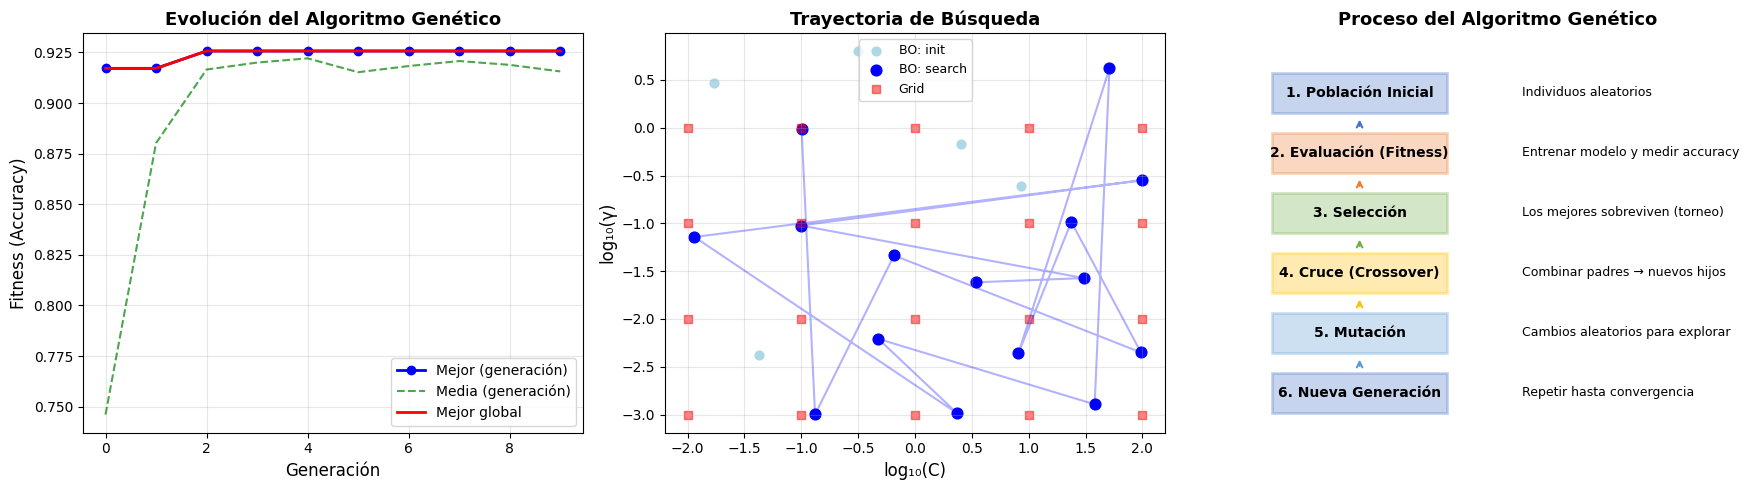

In [ ]:
# --- Visualizar evolución del algoritmo genético ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Evolución del fitness
gens = [h['generation'] for h in ga.historial]
best_fitness = [h['best_fitness'] for h in ga.historial]
mean_fitness = [h['mean_fitness'] for h in ga.historial]
global_best = [h['best_global'] for h in ga.historial]

axes[0].plot(gens, best_fitness, 'b-o', label='Mejor (generación)', linewidth=2, markersize=6)
axes[0].plot(gens, mean_fitness, 'g--', label='Media (generación)', linewidth=1.5, alpha=0.7)
axes[0].plot(gens, global_best, 'r-', label='Mejor global', linewidth=2)
axes[0].set_xlabel('Generación', fontsize=12)
axes[0].set_ylabel('Fitness (Accuracy)', fontsize=12)
axes[0].set_title('Evolución del Algoritmo Genético', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Trayectoria de búsqueda en el espacio
X_obs_bo = np.array(bo_svm.X_observados)
axes[1].scatter(X_obs_bo[:5, 0], X_obs_bo[:5, 1], c='lightblue', s=40, label='BO: init')
axes[1].scatter(X_obs_bo[5:, 0], X_obs_bo[5:, 1], c='blue', s=60, label='BO: search')
axes[1].plot(X_obs_bo[5:, 0], X_obs_bo[5:, 1], 'b-', alpha=0.3)

# Grid points
gx_log = np.log10(np.array(param_grid_svm['C']))
gy_log = np.log10(np.array(param_grid_svm['gamma']))
gx_grid, gy_grid = np.meshgrid(gx_log, gy_log)
axes[1].scatter(gx_grid.flatten(), gy_grid.flatten(), c='red', s=30, marker='s', label='Grid', alpha=0.5)

axes[1].set_xlabel('log₁₀(C)', fontsize=12)
axes[1].set_ylabel('log₁₀(γ)', fontsize=12)
axes[1].set_title('Trayectoria de Búsqueda', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# 3. Diagrama del proceso genético
axes[2].axis('off')
proceso = [
    ("1. Población Inicial", "Individuos aleatorios"),
    ("2. Evaluación (Fitness)", "Entrenar modelo y medir accuracy"),
    ("3. Selección", "Los mejores sobreviven (torneo)"),
    ("4. Cruce (Crossover)", "Combinar padres → nuevos hijos"),
    ("5. Mutación", "Cambios aleatorios para explorar"),
    ("6. Nueva Generación", "Repetir hasta convergencia"),
]
colors = ['#4472C4', '#ED7D31', '#70AD47', '#FFC000', '#5B9BD5', '#4472C4']

for i, ((titulo, desc), color) in enumerate(zip(proceso, colors)):
    y = 0.85 - i * 0.15
    axes[2].add_patch(plt.Rectangle((0.05, y-0.05), 0.35, 0.1,
                                     facecolor=color, alpha=0.3, edgecolor=color, linewidth=2))
    axes[2].text(0.225, y, titulo, ha='center', va='center', fontsize=10, fontweight='bold')
    axes[2].text(0.55, y, desc, ha='left', va='center', fontsize=9)
    if i < 5:
        axes[2].annotate('', xy=(0.225, y-0.06), xytext=(0.225, y-0.09),
                        arrowprops=dict(arrowstyle='->', lw=1.5, color=color))

axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)
axes[2].set_title('Proceso del Algoritmo Genético', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## Successive Halving (Eliminación Sucesiva)

### Idea: Eliminar Candidatos Malos Tempranamente

¿Por qué entrenar completamente 100 configuraciones si la mayoría son malas?

**Successive Halving** asigna un presupuesto limitado a muchas configuraciones
y elimina la mitad peor en cada ronda:

```
Ronda 0: 16 configs × 1 época cada una    → Evaluar
Ronda 1:  8 configs × 2 épocas cada una   → Eliminar las 8 peores
Ronda 2:  4 configs × 4 épocas cada una   → Eliminar las 4 peores
Ronda 3:  2 configs × 8 épocas cada una   → Eliminar las 2 peores
Ronda 4:  1 config  × 16 épocas           → ¡Ganador!
```

**Presupuesto total**: $16 \times 1 + 8 \times 2 + 4 \times 4 + 2 \times 8 + 1 \times 16 = 64$ épocas

vs entrenar las 16 completas: $16 \times 16 = 256$ épocas → **4× más eficiente**

### Formalización

Dado:
- $n$: número de configuraciones iniciales
- $B$: presupuesto total
- $\eta$: factor de reducción (típicamente 3)

En cada ronda $i$:
- Configuraciones activas: $n_i = \lfloor n \cdot \eta^{-i} \rfloor$
- Presupuesto por config: $r_i = r_0 \cdot \eta^i$

In [ ]:
# =============================================================================
# SUCCESSIVE HALVING - Implementación desde cero
# =============================================================================

class SuccessiveHalving:
    """
    Successive Halving para optimización de hiperparámetros.

    Evalúa muchas configuraciones con poco presupuesto,
    y elimina la mitad peor en cada ronda.
    """

    def __init__(self, param_sampler, eta=3, random_state=42):
        """
        Args:
            param_sampler: función que genera configuraciones aleatorias
            eta: factor de reducción (elimina 1/eta en cada ronda)
        """
        self.param_sampler = param_sampler
        self.eta = eta
        self.rng = np.random.RandomState(random_state)
        self.historial = []

    def optimizar(self, evaluar_fn, n_configs=27, min_budget=1, max_budget=27):
        """
        Args:
            evaluar_fn(config, budget): evalúa config con presupuesto budget
            n_configs: número inicial de configuraciones
            min_budget: presupuesto mínimo por config
            max_budget: presupuesto máximo
        """
        import math

        # Generar configuraciones iniciales
        configs = [self.param_sampler(self.rng) for _ in range(n_configs)]

        # Calcular número de rondas
        s_max = int(math.floor(math.log(n_configs, self.eta)))

        # Budget por ronda
        n_i = n_configs
        budget_i = min_budget

        total_evals = 0

        print(f"Successive Halving: {n_configs} configs, η={self.eta}")
        print(f"{'Ronda':>6} | {'Configs':>8} | {'Budget':>8} | {'Mejor Score':>12} | {'Total Evals':>12}")
        print("-" * 60)

        for ronda in range(s_max + 1):
            n_i = max(1, int(n_configs * self.eta ** (-ronda)))
            budget_i = min(max_budget, int(min_budget * self.eta ** ronda))

            # Evaluar cada configuración con el presupuesto actual
            scores = []
            for config in configs[:n_i]:
                score = evaluar_fn(config, budget_i)
                scores.append(score)
                total_evals += 1

            # Ordenar por score (mejor primero)
            indices = np.argsort(scores)[::-1]
            configs = [configs[i] for i in indices]
            scores = [scores[i] for i in indices]

            self.historial.append({
                'round': ronda,
                'n_configs': n_i,
                'budget': budget_i,
                'best_score': scores[0],
                'scores': scores.copy(),
                'total_evals': total_evals
            })

            print(f"  {ronda:>4} | {n_i:>8} | {budget_i:>8} | {scores[0]:>12.4f} | {total_evals:>12}")

            # Eliminar la peor fracción (1 - 1/eta)
            n_keep = max(1, int(n_i / self.eta))
            configs = configs[:n_keep]

        return configs[0], scores[0], total_evals

# --- Successive Halving para Random Forest ---
# "Budget" = n_estimators (más árboles = más presupuesto)
X_rf, y_rf = load_digits(return_X_y=True)
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.3, random_state=42
)

def sampler_rf(rng):
    """Genera configuración aleatoria para Random Forest."""
    return {
        'max_depth': rng.choice([3, 5, 7, 10, 15, 20, None]), # Removed int() cast
        'min_samples_split': int(rng.randint(2, 20)),
        'min_samples_leaf': int(rng.randint(1, 10)),
        'max_features': rng.choice(['sqrt', 'log2', None]),
    }

def evaluar_rf(config, budget):
    """Evalúa Random Forest con n_estimators=budget."""
    params = {k: v for k, v in config.items()}
    params['n_estimators'] = int(budget)
    params['random_state'] = 42

    rf = RandomForestClassifier(**params)
    scores = cross_val_score(rf, X_train_rf, y_train_rf, cv=3)
    return scores.mean()

start = time.time()
sh = SuccessiveHalving(sampler_rf, eta=3, random_state=42)
best_config_sh, best_score_sh, total_evals_sh = sh.optimizar(
    evaluar_rf, n_configs=27, min_budget=5, max_budget=100
)
tiempo_sh = time.time() - start

print(f"\n{'='*60}")
print(f"Resultado Successive Halving (Random Forest)")
print(f"{'='*60}")
print(f"  Mejor score: {best_score_sh:.4f}")
print(f"  Mejor config: {best_config_sh}")
print(f"  Total evaluaciones: {total_evals_sh}")
print(f"  Tiempo: {tiempo_sh:.2f}s")

Successive Halving: 27 configs, η=3
 Ronda |  Configs |   Budget |  Mejor Score |  Total Evals
------------------------------------------------------------
     0 |       27 |        5 |       0.8831 |           27
     1 |        9 |       15 |       0.9276 |           36
     2 |        3 |       45 |       0.9491 |           39
     3 |        1 |      100 |       0.9451 |           40

Resultado Successive Halving (Random Forest)
  Mejor score: 0.9451
  Mejor config: {'max_depth': None, 'min_samples_split': 9, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
  Total evaluaciones: 40
  Tiempo: 11.39s


## Hyperband: Lo Mejor de Ambos Mundos

### El problema de Successive Halving

SH requiere elegir el trade-off entre:
- **Muchas configuraciones** con poco presupuesto (exploración amplia)
- **Pocas configuraciones** con mucho presupuesto (exploración profunda)

### La solución de Hyperband

**Hyperband ejecuta Successive Halving múltiples veces** con diferentes balances:

```
Bracket 0 (muchas configs, poco budget):     81 configs × budget 1 → 3 → 9 → 27 → 81
Bracket 1 (balance medio):                    27 configs × budget 3 → 9 → 27 → 81
Bracket 2 (pocas configs, más budget):         9 configs × budget 9 → 27 → 81
Bracket 3 (muy pocas, mucho budget):           3 configs × budget 27 → 81
Bracket 4 (1 config, budget máximo):           1 config  × budget 81
```

Cada bracket es un Successive Halving con diferente n_configs y min_budget.
El mejor resultado de todos los brackets gana.

### Ventaja teórica

Hyperband tiene **garantías teóricas**:
a lo sumo un factor logarítmico peor que el óptimo.

$$\text{Regret}_{\text{Hyperband}} \leq O(\sqrt{B \cdot \log(B)})$$

In [ ]:
# =============================================================================
# HYPERBAND - Implementación desde cero
# =============================================================================

class Hyperband:
    """
    Hyperband: ejecuta múltiples rondas de Successive Halving
    con diferentes configuraciones de n_configs y min_budget.
    """

    def __init__(self, param_sampler, max_budget=81, eta=3, random_state=42):
        self.param_sampler = param_sampler
        self.max_budget = max_budget
        self.eta = eta
        self.rng = np.random.RandomState(random_state)
        self.historial_brackets = []

    def optimizar(self, evaluar_fn):
        import math

        R = self.max_budget
        eta = self.eta
        s_max = int(math.floor(math.log(R, eta)))
        B = (s_max + 1) * R  # presupuesto total por bracket

        mejor_global = None
        mejor_score_global = -np.inf
        total_evals = 0

        print(f"Hyperband: R={R}, η={eta}, s_max={s_max}")
        print(f"Brackets: {s_max + 1}")
        print("=" * 70)

        for s in range(s_max, -1, -1):
            n = int(math.ceil(B / R * eta**s / (s + 1)))
            r = R * eta**(-s)

            # Generar configuraciones
            configs = [self.param_sampler(self.rng) for _ in range(n)]

            print(f"\n--- Bracket {s_max - s} (s={s}): {n} configs, budget_init={r:.0f} ---")

            bracket_results = []

            for i in range(s + 1):
                n_i = max(1, int(n * eta**(-i)))
                r_i = min(R, r * eta**i)

                # Evaluar
                scores = []
                for config in configs[:n_i]:
                    score = evaluar_fn(config, int(r_i))
                    scores.append(score)
                    total_evals += 1

                # Ordenar y eliminar
                indices = np.argsort(scores)[::-1]
                configs = [configs[idx] for idx in indices]
                scores = [scores[idx] for idx in indices]

                bracket_results.append({
                    'round': i, 'n_configs': n_i, 'budget': int(r_i),
                    'best_score': scores[0]
                })

                n_keep = max(1, int(n_i / eta))
                configs = configs[:n_keep]

                print(f"    Ronda {i}: {n_i} configs × budget={int(r_i)} → best={scores[0]:.4f}")

            # Mejor de este bracket
            if scores[0] > mejor_score_global:
                mejor_score_global = scores[0]
                mejor_global = configs[0]

            self.historial_brackets.append(bracket_results)

        print(f"\n{'='*70}")
        print(f"Total evaluaciones: {total_evals}")

        return mejor_global, mejor_score_global, total_evals

# --- Hyperband para Random Forest ---
start = time.time()
hb = Hyperband(sampler_rf, max_budget=81, eta=3, random_state=42)
best_config_hb, best_score_hb, total_evals_hb = hb.optimizar(evaluar_rf)
tiempo_hb = time.time() - start

print(f"\nResultado Hyperband:")
print(f"  Mejor score: {best_score_hb:.4f}")
print(f"  Mejor config: {best_config_hb}")
print(f"  Evaluaciones: {total_evals_hb}")
print(f"  Tiempo: {tiempo_hb:.2f}s")

Hyperband: R=81, η=3, s_max=4
Brackets: 5

--- Bracket 0 (s=4): 81 configs, budget_init=1 ---
    Ronda 0: 81 configs × budget=1 → best=0.7812
    Ronda 1: 27 configs × budget=3 → best=0.8488
    Ronda 2: 9 configs × budget=9 → best=0.9165
    Ronda 3: 3 configs × budget=27 → best=0.9491
    Ronda 4: 1 configs × budget=81 → best=0.9562

--- Bracket 1 (s=3): 34 configs, budget_init=3 ---
    Ronda 0: 34 configs × budget=3 → best=0.8512
    Ronda 1: 11 configs × budget=9 → best=0.9196
    Ronda 2: 3 configs × budget=27 → best=0.9515
    Ronda 3: 1 configs × budget=81 → best=0.9570

--- Bracket 2 (s=2): 15 configs, budget_init=9 ---
    Ronda 0: 15 configs × budget=9 → best=0.9125
    Ronda 1: 5 configs × budget=27 → best=0.9467
    Ronda 2: 1 configs × budget=81 → best=0.9491

--- Bracket 3 (s=1): 8 configs, budget_init=27 ---
    Ronda 0: 8 configs × budget=27 → best=0.9467
    Ronda 1: 2 configs × budget=81 → best=0.9547

--- Bracket 4 (s=0): 5 configs, budget_init=81 ---
    Ronda 0: 

Grid Search: 18 combinaciones a evaluar
------------------------------------------------------------
Random Search: 20 evaluaciones aleatorias
------------------------------------------------------------


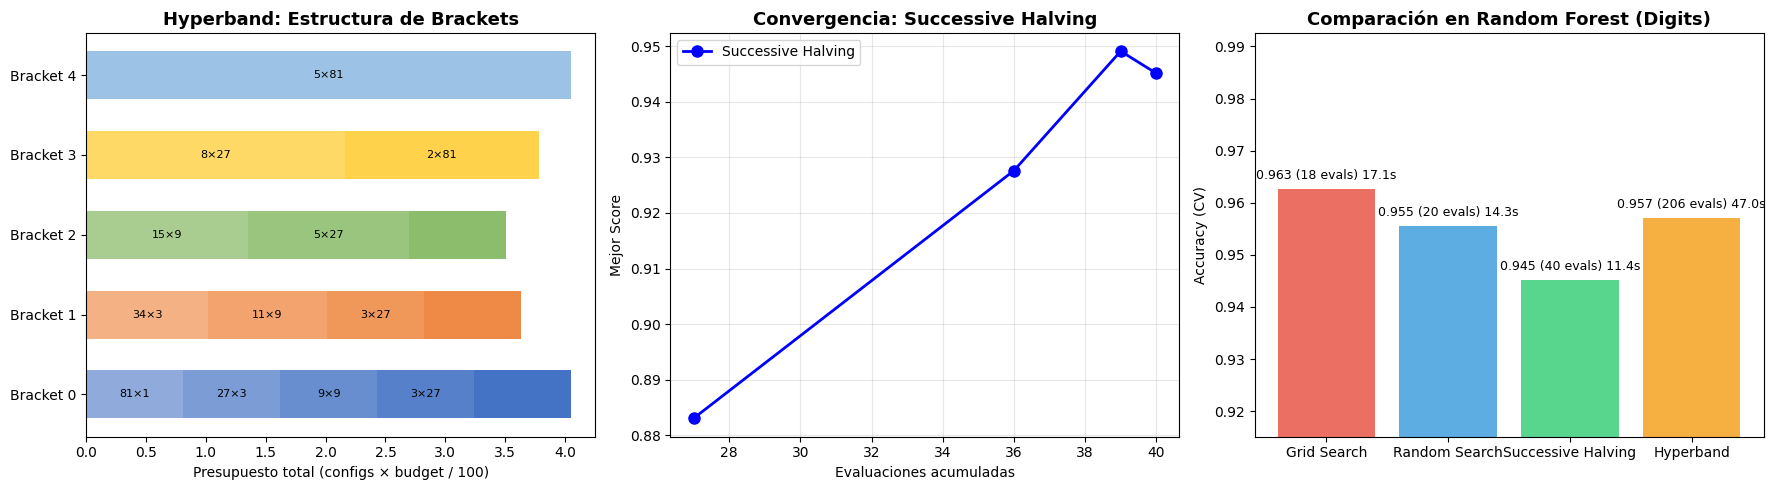

In [ ]:
# --- Visualización de Hyperband vs Successive Halving ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Estructura de brackets de Hyperband
import math
R = 81; eta = 3
s_max = int(math.floor(math.log(R, eta)))

bracket_data = []
for s in range(s_max, -1, -1):
    n = int(math.ceil((s_max+1)*R / R * eta**s / (s+1)))
    r = R * eta**(-s)
    rounds = []
    for i in range(s+1):
        n_i = max(1, int(n * eta**(-i)))
        r_i = min(R, r * eta**i)
        rounds.append((n_i, int(r_i)))
    bracket_data.append(rounds)

colors_br = ['#4472C4', '#ED7D31', '#70AD47', '#FFC000', '#5B9BD5']
for b_idx, rounds in enumerate(bracket_data):
    for r_idx, (n_i, r_i) in enumerate(rounds):
        axes[0].barh(b_idx, r_i * n_i / 100, left=sum(rr*nn/100 for nn, rr in rounds[:r_idx]),
                    color=colors_br[b_idx], alpha=0.6 + 0.1*r_idx, height=0.6)
        if n_i > 1:
            axes[0].text(sum(rr*nn/100 for nn, rr in rounds[:r_idx]) + r_i*n_i/200, b_idx,
                        f'{n_i}×{r_i}', ha='center', va='center', fontsize=8)

axes[0].set_yticks(range(len(bracket_data)))
axes[0].set_yticklabels([f'Bracket {i}' for i in range(len(bracket_data))])
axes[0].set_xlabel('Presupuesto total (configs × budget / 100)')
axes[0].set_title('Hyperband: Estructura de Brackets', fontsize=13, fontweight='bold')

# 2. Convergencia de SH
sh_scores = [h['best_score'] for h in sh.historial]
sh_evals = [h['total_evals'] for h in sh.historial]
axes[1].plot(sh_evals, sh_scores, 'bo-', linewidth=2, markersize=8, label='Successive Halving')
axes[1].set_xlabel('Evaluaciones acumuladas')
axes[1].set_ylabel('Mejor Score')
axes[1].set_title('Convergencia: Successive Halving', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Comparación de métodos en RF
# Quick grid y random para RF
start = time.time()
rf_grid_params = {
    'n_estimators': [50], 'max_depth': [5, 10, 20],
    'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 3],
}
_, score_grid_rf, results_grid_rf = grid_search(
    RandomForestClassifier, rf_grid_params, X_train_rf, y_train_rf, cv=3
)
t_grid_rf = time.time() - start

start = time.time()
rf_random_params = {
    'n_estimators': [50],
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': (2, 20),
    'min_samples_leaf': (1, 10),
    'max_features': ['sqrt', 'log2', None],
}
_, score_random_rf, results_random_rf = random_search(
    RandomForestClassifier, rf_random_params, X_train_rf, y_train_rf, n_iter=20, cv=3
)
t_random_rf = time.time() - start

methods = ['Grid Search', 'Random Search', 'Successive Halving', 'Hyperband']
scores_rf = [score_grid_rf, score_random_rf, best_score_sh, best_score_hb]
evals_rf = [len(results_grid_rf), 20, total_evals_sh, total_evals_hb]
times_rf = [t_grid_rf, t_random_rf, tiempo_sh, tiempo_hb]

x = np.arange(len(methods))
bars = axes[2].bar(x, scores_rf, color=['#E74C3C', '#3498DB', '#2ECC71', '#F39C12'], alpha=0.8)
axes[2].set_xticks(x)
axes[2].set_xticklabels(methods, fontsize=10)
axes[2].set_ylabel('Accuracy (CV)')
axes[2].set_title('Comparación en Random Forest (Digits)', fontsize=13, fontweight='bold')

for bar, score, evals, t in zip(bars, scores_rf, evals_rf, times_rf):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{score:.3f} ({evals} evals) {t:.1f}s', ha='center', fontsize=9)

axes[2].set_ylim(min(scores_rf) - 0.03, max(scores_rf) + 0.03)

plt.tight_layout()
plt.show()

## 8. Comparación Final de Todas las Técnicas

In [ ]:
# =============================================================================
# COMPARACIÓN COMPLETA EN MÚLTIPLES MODELOS
# =============================================================================

print("=" * 70)
print("COMPARACIÓN FINAL: Todos los Métodos en Gradient Boosting (Digits)")
print("=" * 70)

# Usar GradientBoosting con más hiperparámetros

def evaluar_gb(params_vec):
    """Evalúa Gradient Boosting."""
    lr = 10 ** params_vec[0]  # log scale
    max_depth = int(np.clip(params_vec[1], 2, 15))
    n_est = int(np.clip(params_vec[2] * 50, 20, 300))

    gb = GradientBoostingClassifier(
        learning_rate=lr, max_depth=max_depth, n_estimators=n_est, random_state=42
    )
    scores = cross_val_score(gb, X_train_rf, y_train_rf, cv=3)
    return scores.mean()

# 1. Grid Search
print("\n1. Grid Search...")
param_grid_gb = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100, 200],
}
start = time.time()
_, score_grid_gb, res_grid_gb = grid_search(
    GradientBoostingClassifier, param_grid_gb, X_train_rf, y_train_rf, cv=3
)
t1 = time.time() - start
n1 = len(res_grid_gb)

# 2. Random Search
print("\n2. Random Search...")
param_random_gb = {
    'learning_rate': (0.01, 0.3, 'log'),
    'max_depth': (2, 10),
    'n_estimators': (30, 250),
}
start = time.time()
_, score_rand_gb, res_rand_gb = random_search(
    GradientBoostingClassifier, param_random_gb, X_train_rf, y_train_rf, n_iter=20, cv=3
)
t2 = time.time() - start
n2 = 20

# 3. Bayesian
print("\n3. Optimización Bayesiana...")
start = time.time()
bo_gb = OptimizacionBayesiana(bounds=[(-2, -0.5), (2, 15), (0.5, 5)], random_state=42)
best_params_bo_gb, best_score_bo_gb = bo_gb.optimizar(evaluar_gb, n_init=5, n_iter=15)
t3 = time.time() - start
n3 = len(bo_gb.X_observados)

# 4. Genético
print("\n4. Algoritmo Genético...")
start = time.time()
ga_gb = AlgoritmoGeneticoHP(bounds=[(-2, -0.5), (2, 15), (0.5, 5)],
                            pop_size=12, n_generations=8, random_state=42)
best_params_ga_gb, best_score_ga_gb = ga_gb.optimizar(evaluar_gb)
t4 = time.time() - start
n4 = 12 * 8  # pop × gens

# Tabla resumen
print(f"\n\n{'='*80}")
print(f"TABLA RESUMEN FINAL")
print(f"{'='*80}")
print(f"{'Método':<25} {'Score':>8} {'Evals':>8} {'Tiempo':>10} {'Tipo':>20}")
print(f"{'-'*80}")
print(f"{'Grid Search':<25} {score_grid_gb:>8.4f} {n1:>8} {t1:>9.1f}s {'Exhaustivo':>20}")
print(f"{'Random Search':<25} {score_rand_gb:>8.4f} {n2:>8} {t2:>9.1f}s {'Aleatorio':>20}")
print(f"{'Bayesian (GP+EI)':<25} {best_score_bo_gb:>8.4f} {n3:>8} {t3:>9.1f}s {'Model-based':>20}")
print(f"{'Genetic Algorithm':<25} {best_score_ga_gb:>8.4f} {n4:>8} {t4:>9.1f}s {'Evolutivo':>20}")
print(f"{'Successive Halving':<25} {best_score_sh:>8.4f} {total_evals_sh:>8} {tiempo_sh:>9.1f}s {'Early-stopping':>20}")
print(f"{'Hyperband':<25} {best_score_hb:>8.4f} {total_evals_hb:>8} {tiempo_hb:>9.1f}s {'Adaptive':>20}")

COMPARACIÓN FINAL: Todos los Métodos en Gradient Boosting (Digits)

1. Grid Search...
Grid Search: 36 combinaciones a evaluar
------------------------------------------------------------

2. Random Search...
Random Search: 20 evaluaciones aleatorias
------------------------------------------------------------

3. Optimización Bayesiana...

4. Algoritmo Genético...
Algoritmo Genético: 12 individuos × 8 generaciones
------------------------------------------------------------
  Gen   5 | Mejor: 0.9602 | Media: 0.9554 | Global: 0.9602

  Total evaluaciones: 96


TABLA RESUMEN FINAL
Método                       Score    Evals     Tiempo                 Tipo
--------------------------------------------------------------------------------
Grid Search                 0.9515       36    1131.0s           Exhaustivo
Random Search               0.9547       20     988.4s            Aleatorio
Bayesian (GP+EI)            0.9618       20     811.0s          Model-based
Genetic Algorithm           0

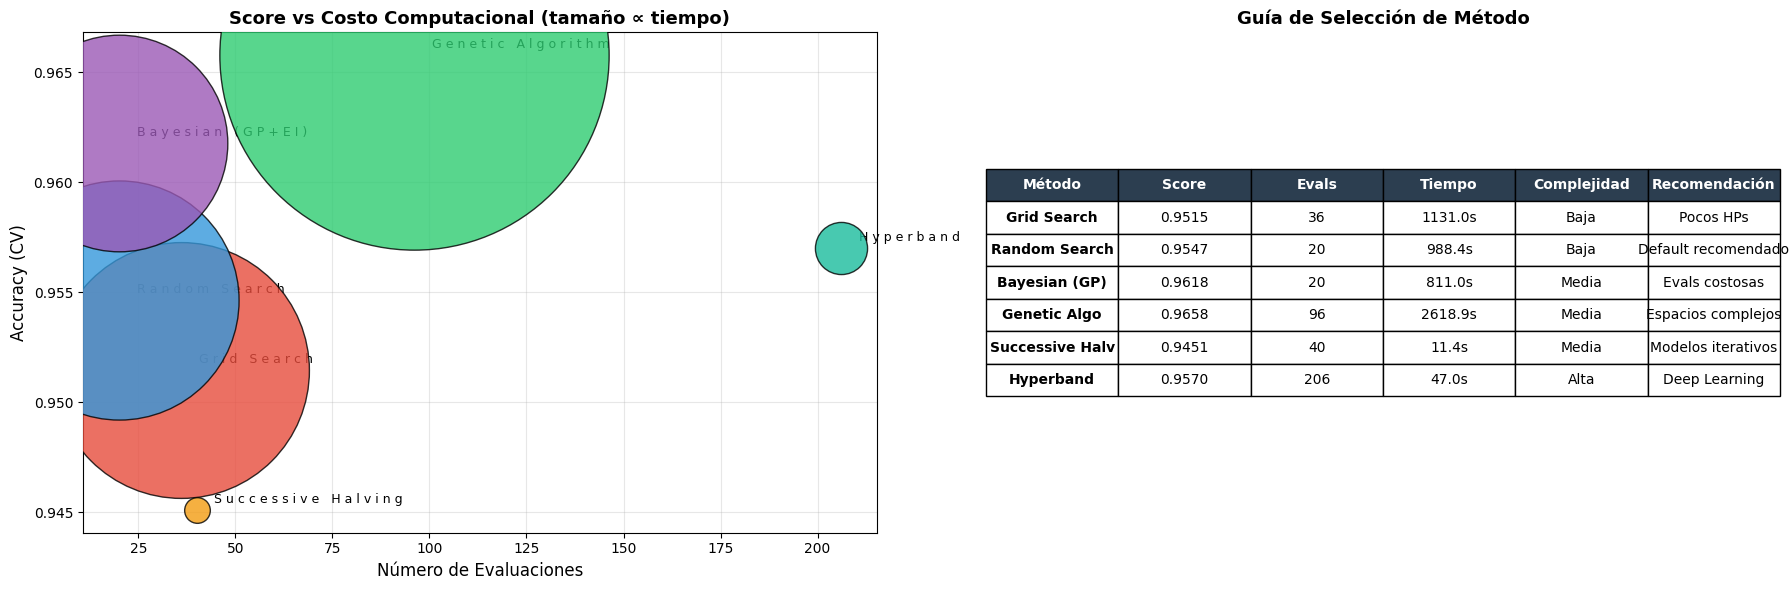

In [ ]:
# --- Visualización final ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Accuracy vs Evaluaciones
methods_all = ['Grid Search', 'Random Search', 'Bayesian (GP+EI)',
               'Genetic Algorithm', 'Successive Halving', 'Hyperband']
scores_all = [score_grid_gb, score_rand_gb, best_score_bo_gb,
              best_score_ga_gb, best_score_sh, best_score_hb]
evals_all = [n1, n2, n3, n4, total_evals_sh, total_evals_hb]
times_all = [t1, t2, t3, t4, tiempo_sh, tiempo_hb]
colors_all = ['#E74C3C', '#3498DB', '#9B59B6', '#2ECC71', '#F39C12', '#1ABC9C']

# Scatter: score vs evaluaciones
for i, (method, score, n_eval, t, c) in enumerate(
    zip(methods_all, scores_all, evals_all, times_all, colors_all)):
    axes[0].scatter(n_eval, score, s=max(200, t*30), c=c, alpha=0.8,
                   edgecolors='black', linewidth=1, zorder=5)
    axes[0].annotate(method.replace('', ' '), (n_eval, score),
                    textcoords="offset points", xytext=(10, 5), fontsize=9)

axes[0].set_xlabel('Número de Evaluaciones', fontsize=12)
axes[0].set_ylabel('Accuracy (CV)', fontsize=12)
axes[0].set_title('Score vs Costo Computacional (tamaño ∝ tiempo)', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. Radar chart / tabla visual
categorias = ['Score', 'Eficiencia (menos evals)', 'Velocidad (menos tiempo)',
              'Simplicidad', 'Exploración']

# Normalizar métricas a [0, 1]
max_score = max(scores_all)
min_score = min(scores_all)
max_evals = max(evals_all)
max_time = max(times_all)

metodos_radar = {
    'Grid Search': [
        (score_grid_gb - min_score) / (max_score - min_score + 1e-10),
        1 - n1/max_evals, 1 - t1/max_time, 1.0, 0.3
    ],
    'Random Search': [
        (score_rand_gb - min_score) / (max_score - min_score + 1e-10),
        1 - n2/max_evals, 1 - t2/max_time, 0.9, 0.7
    ],
    'Bayesian': [
        (best_score_bo_gb - min_score) / (max_score - min_score + 1e-10),
        1 - n3/max_evals, 1 - t3/max_time, 0.4, 0.9
    ],
    'Genetic': [
        (best_score_ga_gb - min_score) / (max_score - min_score + 1e-10),
        1 - n4/max_evals, 1 - t4/max_time, 0.3, 0.8
    ],
}

# Tabla resumen como gráfico
axes[1].axis('off')
table_data = [
    ['Método', 'Score', 'Evals', 'Tiempo', 'Complejidad', 'Recomendación'],
    ['Grid Search', f'{score_grid_gb:.4f}', str(n1), f'{t1:.1f}s', 'Baja', 'Pocos HPs'],
    ['Random Search', f'{score_rand_gb:.4f}', str(n2), f'{t2:.1f}s', 'Baja', 'Default recomendado'],
    ['Bayesian (GP)', f'{best_score_bo_gb:.4f}', str(n3), f'{t3:.1f}s', 'Media', 'Evals costosas'],
    ['Genetic Algo', f'{best_score_ga_gb:.4f}', str(n4), f'{t4:.1f}s', 'Media', 'Espacios complejos'],
    ['Successive Halv', f'{best_score_sh:.4f}', str(total_evals_sh), f'{tiempo_sh:.1f}s', 'Media', 'Modelos iterativos'],
    ['Hyperband', f'{best_score_hb:.4f}', str(total_evals_hb), f'{tiempo_hb:.1f}s', 'Alta', 'Deep Learning'],
]

table = axes[1].table(cellText=table_data[1:], colLabels=table_data[0],
                      loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.8)
for i in range(len(table_data[0])):
    table[0, i].set_facecolor('#2C3E50')
    table[0, i].set_text_props(color='white', fontweight='bold')
for row in range(1, len(table_data)):
    table[row, 0].set_text_props(fontweight='bold')

axes[1].set_title('Guía de Selección de Método', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## Resumen y Recomendaciones

### Recapitulación: Parámetros vs Hiperparámetros

| | Parámetros | Hiperparámetros |
|---|-----------|----------------|
| **¿Quién los define?** | El algoritmo (automático) | El humano / algoritmo de búsqueda |
| **¿Cuándo?** | Durante el entrenamiento | Antes del entrenamiento |
| **¿Cómo se ajustan?** | Gradient descent, etc. | Grid, Random, Bayesian, etc. |
| **Ejemplos** | Pesos $w$, bias $b$ | Learning rate, n_layers, dropout |

### Guía de selección del método

```
¿Cuántos hiperparámetros?
│
├── 1-2 HPs → Grid Search (simple y exhaustivo)
│
├── 3-5 HPs
│   ├── Evaluaciones baratas → Random Search (Bergstra & Bengio)
│   └── Evaluaciones costosas → Bayesian Optimization
│
└── 5+ HPs
    ├── Modelo iterativo (NN) → Hyperband / Successive Halving
    ├── Espacio complejo → Algoritmo Genético
    └── En la práctica → Random Search + ajuste manual
```

### Resumen de técnicas

| Técnica | Complejidad | Mejor para | Paper clave |
|---------|------------|-----------|-------------|
| **Grid Search** | $O(\prod n_i)$ | Pocos HPs, exhaustivo | - |
| **Random Search** | $O(n)$ | Default recomendado | Bergstra & Bengio 2012 |
| **Bayesian (GP)** | $O(n^3)$ por iter | Evals costosas | Snoek et al. 2012 |
| **Genetic Algorithm** | $O(pop \times gen)$ | Espacios no estándar | - |
| **Successive Halving** | $O(n \log n)$ | Modelos iterativos | Jamieson & Talwalkar 2016 |
| **Hyperband** | $O(n \log^2 n)$ | Deep Learning | Li et al. 2017 |

### En la práctica (industria y research):
1. **Empezar con Random Search** (simple, efectivo, bien fundamentado)
2. **Si las evaluaciones son costosas** → Bayesian (Optuna, Ax)
3. **Si entrenas redes neuronales** → Hyperband (integrado en Ray Tune, Optuna)
4. **Grid Search** solo para exploración inicial con 1-2 hiperparámetros

---

### Referencias

1. Bergstra, J. & Bengio, Y. (2012). **"Random Search for Hyper-Parameter Optimization"**. JMLR.
2. Snoek, J., Larochelle, H. & Adams, R. (2012). **"Practical Bayesian Optimization"**. NeurIPS.
3. Jamieson, K. & Talwalkar, A. (2016). **"Non-stochastic Best Arm Identification and Hyperparameter Optimization"**. AISTATS.
4. Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A. & Talwalkar, A. (2017). **"Hyperband: A Novel Bandit-Based Approach to Hyperparameter Optimization"**. JMLR.
